# **LIMPIEZA DE DATOS**

Carlos Francisco Montoya Urzua

23 de Marzo de 2026

1. Cargar el dataset




In [2]:
import pandas as pd
import numpy as np



In [48]:
#df = pd.read_csv("ventaCSV.csv")
df = pd.read_excel('venta2excel.xlsx')
#Ver primeras filas:
df.head()

,"id,nombre,edad,ciudad,email,fecha_registro,ventas"
0,"1,Ana Lopez,25,Mexico,ana.lopez@email.com,2023..."
1,"2,Juan Perez,NaN,mexico,juanperez@email,10/02/..."
2,"3,Carlos Ruiz,34,Guadalajara,carlos.ruiz@email..."
3,"4,Maria Diaz,29,MEXICO,maria.diaz@email.com,20..."
4,"5,Pedro Torres,45,Monterrey,pedro.torres@email..."


In [49]:
#TRATAMIENTO DEL DATAFRAME PARA PODERLO USAR
#ESTO SE SUSTENTA EN LO QUE YA HABIA HECHO CON LA EXPLORACION DE DATOS

#LISTA DE COLUMNAS DE NUESTRO DF
columnas = df.columns[0]
columnas = columnas.split(',')

#SE PROCEDE A PARTICIONAR LOS VALORES DE LAS COLUMNAS EN SUBCOLUMNAS SIGUIENDO
df[columnas] = df[df.columns[0]].str.split(',',expand=True)

#ELIMINAR LA PRIMER COLUMNA, QUE ES LA PROBLEMATICA
df = df.drop(columns=[df.columns[0]])

In [5]:
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
1,2,Juan Perez,NaN,mexico,juanperez@email,10/02/2023,200
2,3,Carlos Ruiz,34,Guadalajara,carlos.ruiz@email.com,2023/03/15,150
3,4,Maria Diaz,29,MEXICO,maria.diaz@email.com,2023-04-01,NaN
4,5,Pedro Torres,45,Monterrey,pedro.torres@email.com,2023-05-12,300
5,6,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
6,7,Laura Gomez,31,Guadalajara,laura.gomez@email.com,2023-06-02,250
7,8,Diego Ramos,150,Puebla,diego.ramos@email.com,2023-02-18,180
8,9,Sofia Herrera,28,Mexico,sofia.h@email.com,2023-03-10,220
9,10,Andres Molina,NaN,Monterrey,andres.molina@email.com,2023-03-21,210


2. Revisar estructura del dataset

Esto permite detectar:

•	tipos de datos incorrectos
•	valores faltantes
•	número de columnas





In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              50 non-null     object
 1   nombre          50 non-null     object
 2   edad            50 non-null     object
 3   ciudad          50 non-null     object
 4   email           50 non-null     object
 5   fecha_registro  50 non-null     object
 6   ventas          50 non-null     object
dtypes: object(7)
memory usage: 2.9+ KB


In [7]:
#Dimensiones del dataset:
df.shape

(50, 7)

3. Eliminar duplicados
Los datasets muchas veces tienen registros repetidos.



In [9]:
#Ver duplicados:
print(df.duplicated().sum())


0


In [50]:
#Eliminar duplicados:
df = df.drop_duplicates()
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
1,2,Juan Perez,NaN,mexico,juanperez@email,10/02/2023,200
2,3,Carlos Ruiz,34,Guadalajara,carlos.ruiz@email.com,2023/03/15,150
3,4,Maria Diaz,29,MEXICO,maria.diaz@email.com,2023-04-01,NaN
4,5,Pedro Torres,45,Monterrey,pedro.torres@email.com,2023-05-12,300
5,6,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
6,7,Laura Gomez,31,Guadalajara,laura.gomez@email.com,2023-06-02,250
7,8,Diego Ramos,150,Puebla,diego.ramos@email.com,2023-02-18,180
8,9,Sofia Herrera,28,Mexico,sofia.h@email.com,2023-03-10,220
9,10,Andres Molina,NaN,Monterrey,andres.molina@email.com,2023-03-21,210


4. Detectar valores faltantes



In [11]:
print(df.isnull().sum())
#Porcentaje de valores faltantes:
print((df.isnull().sum()/len(df))*100)

id                0
nombre            0
edad              0
ciudad            0
email             0
fecha_registro    0
ventas            0
dtype: int64
id                0.0
nombre            0.0
edad              0.0
ciudad            0.0
email             0.0
fecha_registro    0.0
ventas            0.0
dtype: float64


5. Tratar valores faltantes
Hay varias estrategias.

Opción 1: Eliminar filas con NaN
df = df.dropna()

Opción 2: Eliminar columnas con muchos NaN
df = df.drop(columns=["columna"])

Opción 3: Rellenar con media
df["edad"].fillna(df["edad"].mean(), inplace=True)

Opción 4: Rellenar con mediana
df["edad"].fillna(df["edad"].median(), inplace=True)

Opción 5: Rellenar con categoría
df["ciudad"].fillna("Desconocido", inplace=True)


In [51]:
#Opción 5: Rellenar con categoría df["ciudad"].fillna("Desconocido", inplace=True)
df["ciudad"].fillna("Desconocido", inplace=True)

/tmp/ipykernel_23452/3527257606.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["ciudad"].fillna("Desconocido", inplace=True)


In [36]:
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
1,2,Juan Perez,NaN,mexico,juanperez@email,10/02/2023,200
2,3,Carlos Ruiz,34,Guadalajara,carlos.ruiz@email.com,2023/03/15,150
3,4,Maria Diaz,29,MEXICO,maria.diaz@email.com,2023-04-01,NaN
4,5,Pedro Torres,45,Monterrey,pedro.torres@email.com,2023-05-12,300
5,6,Ana Lopez,25,Mexico,ana.lopez@email.com,2023-01-10,120
6,7,Laura Gomez,31,Guadalajara,laura.gomez@email.com,2023-06-02,250
7,8,Diego Ramos,150,Puebla,diego.ramos@email.com,2023-02-18,180
8,9,Sofia Herrera,28,Mexico,sofia.h@email.com,2023-03-10,220
9,10,Andres Molina,NaN,Monterrey,andres.molina@email.com,2023-03-21,210


In [52]:
df.dtypes

,0
id,object
nombre,object
edad,object
ciudad,object
email,object
fecha_registro,object
ventas,object


In [53]:
df['ventas'] = df['ventas'].astype(np.number)
df['edad'] = df['edad'].astype(np.number)

/usr/local/lib/python3.12/dist-packages/pandas/core/dtypes/common.py:1645: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  npdtype = np.dtype(dtype)
/usr/local/lib/python3.12/dist-packages/pandas/core/dtypes/common.py:1645: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  npdtype = np.dtype(dtype)


In [54]:
df.dtypes

,0
id,object
nombre,object
edad,float64
ciudad,object
email,object
fecha_registro,object
ventas,float64


In [55]:
df['ventas'].fillna(0, inplace=True)

/tmp/ipykernel_23452/624367641.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ventas'].fillna(0, inplace=True)


In [56]:
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.0,Mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,NaN,mexico,juanperez@email,10/02/2023,200.0
2,3,Carlos Ruiz,34.0,Guadalajara,carlos.ruiz@email.com,2023/03/15,150.0
3,4,Maria Diaz,29.0,MEXICO,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.0,Monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.0,Mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.0,Guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,150.0,Puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.0,Mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,NaN,Monterrey,andres.molina@email.com,2023-03-21,210.0


In [57]:
#Opción 3: Rellenar con media df["edad"].fillna(df["edad"].mean(), inplace=True)
df["edad"].fillna(df["edad"].mean(), inplace=True)

/tmp/ipykernel_23452/1984018013.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["edad"].fillna(df["edad"].mean(), inplace=True)


In [58]:
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,10/02/2023,200.0
2,3,Carlos Ruiz,34.000000,Guadalajara,carlos.ruiz@email.com,2023/03/15,150.0
3,4,Maria Diaz,29.000000,MEXICO,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,Monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,Guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,150.000000,Puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.000000,Mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,Monterrey,andres.molina@email.com,2023-03-21,210.0


In [59]:
#CORREGIR AQUELLOS QUE APARECEN CON EDAD MENOR A 18
df.loc[df['edad'] < 18, 'edad'] = 18
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,10/02/2023,200.0
2,3,Carlos Ruiz,34.000000,Guadalajara,carlos.ruiz@email.com,2023/03/15,150.0
3,4,Maria Diaz,29.000000,MEXICO,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,Monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,Guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,150.000000,Puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.000000,Mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,Monterrey,andres.molina@email.com,2023-03-21,210.0


In [60]:
#CORREGIR AQUELLOS QUE APARECEN CON EDAD MAYOR A 70
df.loc[df['edad'] > 70, 'edad'] = 70
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,10/02/2023,200.0
2,3,Carlos Ruiz,34.000000,Guadalajara,carlos.ruiz@email.com,2023/03/15,150.0
3,4,Maria Diaz,29.000000,MEXICO,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,Monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,Guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,70.000000,Puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.000000,Mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,Monterrey,andres.molina@email.com,2023-03-21,210.0


6. Corregir tipos de datos
Muchos datasets tienen tipos incorrectos.



In [61]:
#Ver tipos:
print(df.dtypes)





id                 object
nombre             object
edad              float64
ciudad             object
email              object
fecha_registro     object
ventas            float64
dtype: object


In [63]:
#Convertir a número:
#df["ganancias"] = df["ganancias"].astype(str).str.replace('"', '', regex=False)
#df["ganancias"] = pd.to_numeric(df["ganancias"], errors='coerce')
df['edad'] = pd.to_numeric(df["edad"], errors='coerce')
df['ventas'] = pd.to_numeric(df["ventas"], errors='coerce')
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,10/02/2023,200.0
2,3,Carlos Ruiz,34.000000,Guadalajara,carlos.ruiz@email.com,2023/03/15,150.0
3,4,Maria Diaz,29.000000,MEXICO,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,Monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,Guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,70.000000,Puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.000000,Mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,Monterrey,andres.molina@email.com,2023-03-21,210.0


In [65]:
#Convertir a fecha:
#df['fecha_registro'] = pd.to_datetime(df['fecha_registro'])#falla
df['fecha_registro'] = pd.to_datetime(df['fecha_registro'], format='mixed')

In [66]:
#Convertir a categoría:
df["cudad"] = df["ciudad"].astype("category")
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas,cudad
0,1,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0,Mexico
1,2,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0,mexico
2,3,Carlos Ruiz,34.000000,Guadalajara,carlos.ruiz@email.com,2023-03-15,150.0,Guadalajara
3,4,Maria Diaz,29.000000,MEXICO,maria.diaz@email.com,2023-04-01,0.0,MEXICO
4,5,Pedro Torres,45.000000,Monterrey,pedro.torres@email.com,2023-05-12,300.0,Monterrey
5,6,Ana Lopez,25.000000,Mexico,ana.lopez@email.com,2023-01-10,120.0,Mexico
6,7,Laura Gomez,31.000000,Guadalajara,laura.gomez@email.com,2023-06-02,250.0,Guadalajara
7,8,Diego Ramos,70.000000,Puebla,diego.ramos@email.com,2023-02-18,180.0,Puebla
8,9,Sofia Herrera,28.000000,Mexico,sofia.h@email.com,2023-03-10,220.0,Mexico
9,10,Andres Molina,38.767442,Monterrey,andres.molina@email.com,2023-03-21,210.0,Monterrey


7. Estandarizar texto
Problema común:
Mexico
mexico
MEXICO
Solución:



In [67]:
df["ciudad"] = df["ciudad"].str.lower()
#Eliminar espacios:
df["ciudad"] = df["ciudad"].str.strip()
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas,cudad
0,1,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0,Mexico
1,2,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0,mexico
2,3,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0,Guadalajara
3,4,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0,MEXICO
4,5,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0,Monterrey
5,6,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0,Mexico
6,7,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0,Guadalajara
7,8,Diego Ramos,70.000000,puebla,diego.ramos@email.com,2023-02-18,180.0,Puebla
8,9,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0,Mexico
9,10,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0,Monterrey


In [68]:
df = df.drop(columns=df.columns[-1])

In [69]:
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0
2,3,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0
3,4,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0
7,8,Diego Ramos,70.000000,puebla,diego.ramos@email.com,2023-02-18,180.0
8,9,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0


8. Corregir categorías inconsistentes

Ejemplo:
M
Male
Hombre
Solución:


In [70]:
df["genero"] = df["genero"].replace({
    "M":"Male",
    "Hombre":"Male"
})

#NO EXISTE GENERO

KeyError: 'genero'

9. Detectar outliers
Usando boxplot:



<Axes: xlabel='edad'>

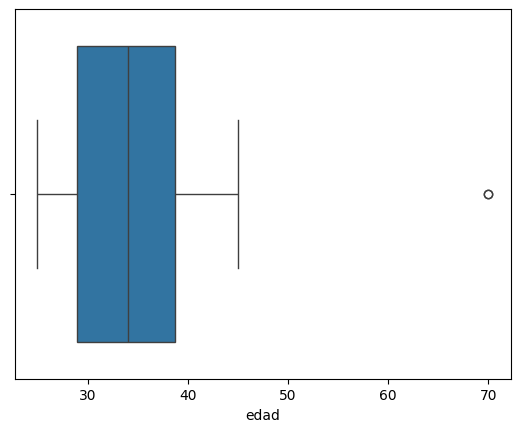

In [71]:
import seaborn as sns
sns.boxplot(x=df["edad"])

Eliminar outliers usando IQR
Q1 = df["salario"].quantile(0.25)
Q3 = df["salario"].quantile(0.75)
IQR = Q3 - Q1
df = df[(df["salario"] >= Q1 - 1.5*IQR) &
        (df["salario"] <= Q3 + 1.5*IQR)]


In [72]:
#Eliminar outliers usando IQR
Q1 = df["edad"].quantile(0.25)
Q3 = df["edad"].quantile(0.75)
IQR = Q3 - Q1
df = df[(df["edad"] >= Q1 - 1.5*IQR) &
        (df["edad"] <= Q3 + 1.5*IQR)]
df

,id,nombre,edad,ciudad,email,fecha_registro,ventas
0,1,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
1,2,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0
2,3,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0
3,4,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0
4,5,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0
5,6,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
6,7,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0
8,9,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0
9,10,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0
10,11,Lucia Castro,26.000000,mexico,lucia.castro@email.com,2023-04-10,190.0


10. Eliminar columnas irrelevantes
Columnas que no aportan información:
•	ID
•	números aleatorios
•	códigos internos
Ejemplo:
df = df.drop(columns=["ID"])


In [73]:
df = df.drop(columns=["id"])

In [74]:
df

,nombre,edad,ciudad,email,fecha_registro,ventas
0,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
1,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0
2,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0
3,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0
4,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0
5,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
6,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0
8,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0
9,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0
10,Lucia Castro,26.000000,mexico,lucia.castro@email.com,2023-04-10,190.0


11. Renombrar columnas
Para mantener nombres claros.
df = df.rename(columns={
    "EdadPersona":"edad",
    "IngresoMensual":"ingreso"
})


In [75]:
df = df.rename(columns={ "edad":"EdadPersona", "ingreso":"IngresoMensual" })

In [76]:
df

,nombre,EdadPersona,ciudad,email,fecha_registro,ventas
0,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
1,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0
2,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0
3,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0
4,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0
5,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
6,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0
8,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0
9,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0
10,Lucia Castro,26.000000,mexico,lucia.castro@email.com,2023-04-10,190.0


In [77]:
df = df.rename(columns={ "EdadPersona":"edad", "IngresoMensual":"ingreso" })

In [78]:
df

,nombre,edad,ciudad,email,fecha_registro,ventas
0,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
1,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0
2,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0
3,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0
4,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0
5,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0
6,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0
8,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0
9,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0
10,Lucia Castro,26.000000,mexico,lucia.castro@email.com,2023-04-10,190.0


12. Crear variables nuevas
Ejemplo:
df["ingreso_anual"] = df["ingreso_mensual"] * 12


In [79]:
df['ingreso_mensual'] = 20000
df["ingreso_anual"] = df["ingreso_mensual"] * 12

In [80]:
df

,nombre,edad,ciudad,email,fecha_registro,ventas,ingreso_mensual,ingreso_anual
0,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0,20000,240000
1,Juan Perez,38.767442,mexico,juanperez@email,2023-10-02,200.0,20000,240000
2,Carlos Ruiz,34.000000,guadalajara,carlos.ruiz@email.com,2023-03-15,150.0,20000,240000
3,Maria Diaz,29.000000,mexico,maria.diaz@email.com,2023-04-01,0.0,20000,240000
4,Pedro Torres,45.000000,monterrey,pedro.torres@email.com,2023-05-12,300.0,20000,240000
5,Ana Lopez,25.000000,mexico,ana.lopez@email.com,2023-01-10,120.0,20000,240000
6,Laura Gomez,31.000000,guadalajara,laura.gomez@email.com,2023-06-02,250.0,20000,240000
8,Sofia Herrera,28.000000,mexico,sofia.h@email.com,2023-03-10,220.0,20000,240000
9,Andres Molina,38.767442,monterrey,andres.molina@email.com,2023-03-21,210.0,20000,240000
10,Lucia Castro,26.000000,mexico,lucia.castro@email.com,2023-04-10,190.0,20000,240000


13. Verificar dataset limpio
Revisar nuevamente:



In [81]:
df.info()



<class 'pandas.core.frame.DataFrame'>
Index: 48 entries, 0 to 49
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   nombre           48 non-null     object        
 1   edad             48 non-null     float64       
 2   ciudad           48 non-null     object        
 3   email            48 non-null     object        
 4   fecha_registro   48 non-null     datetime64[ns]
 5   ventas           48 non-null     float64       
 6   ingreso_mensual  48 non-null     int64         
 7   ingreso_anual    48 non-null     int64         
dtypes: datetime64[ns](1), float64(2), int64(2), object(3)
memory usage: 3.4+ KB


In [82]:
df.describe()



,edad,fecha_registro,ventas,ingreso_mensual,ingreso_anual
count,48.000000,48,48.000000,48.0,48.0
mean,34.132752,2023-05-05 07:30:00,207.604167,20000.0,240000.0
min,25.000000,2023-01-10 00:00:00,0.000000,20000.0,240000.0
25%,29.000000,2023-03-15 00:00:00,190.000000,20000.0,240000.0
50%,34.000000,2023-05-01 00:00:00,225.000000,20000.0,240000.0
75%,38.767442,2023-06-25 18:00:00,260.000000,20000.0,240000.0
max,45.000000,2023-10-02 00:00:00,310.000000,20000.0,240000.0
std,5.865974,NaN,80.039814,0.0,0.0


In [83]:
df.isnull().sum()

,0
nombre,0
edad,0
ciudad,0
email,0
fecha_registro,0
ventas,0
ingreso_mensual,0
ingreso_anual,0
